In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score,recall_score,f1_score
from sklearn.metrics import classification_report

plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')






from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


In [3]:
df=pd.read_csv('diabetes.csv')

## Explore Data

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
df.duplicated().sum()

0

## Analysis Data

In [8]:
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


<Axes: >

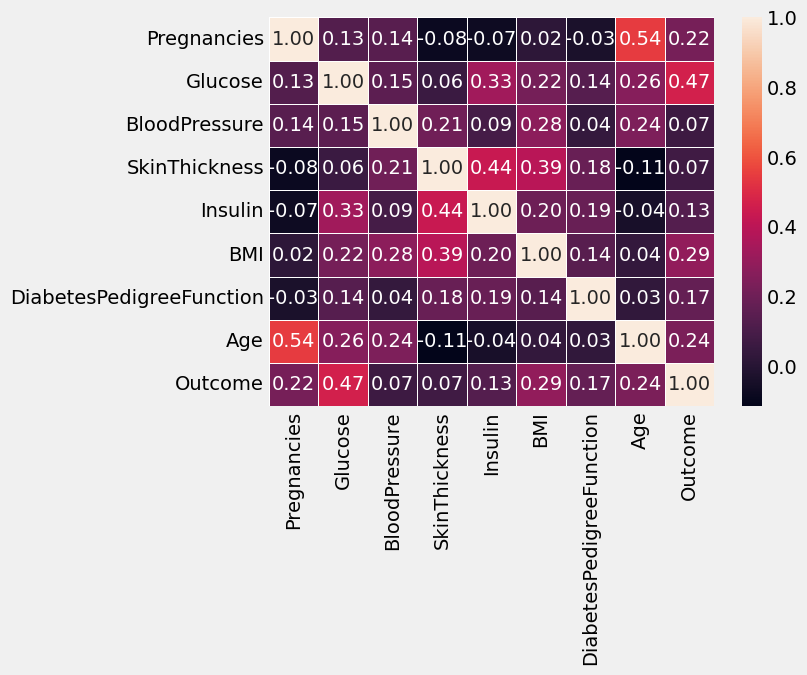

In [9]:
sns.heatmap(df.corr(),annot=True,fmt='0.2f',linewidth=.5)

<Axes: xlabel='Outcome', ylabel='count'>

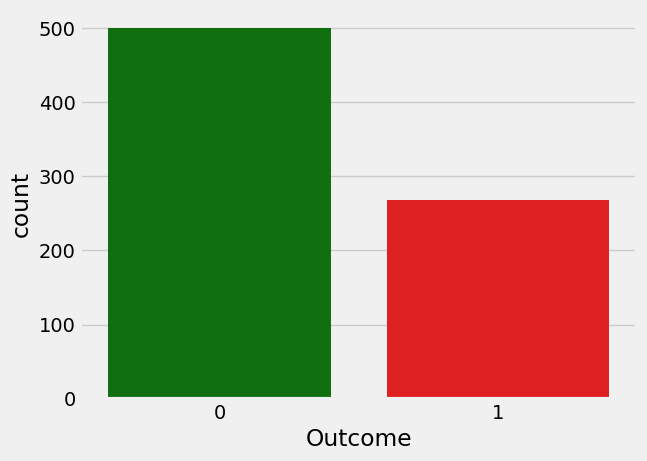

In [10]:
sns.countplot(x="Outcome",data=df,palette=['g','r'])

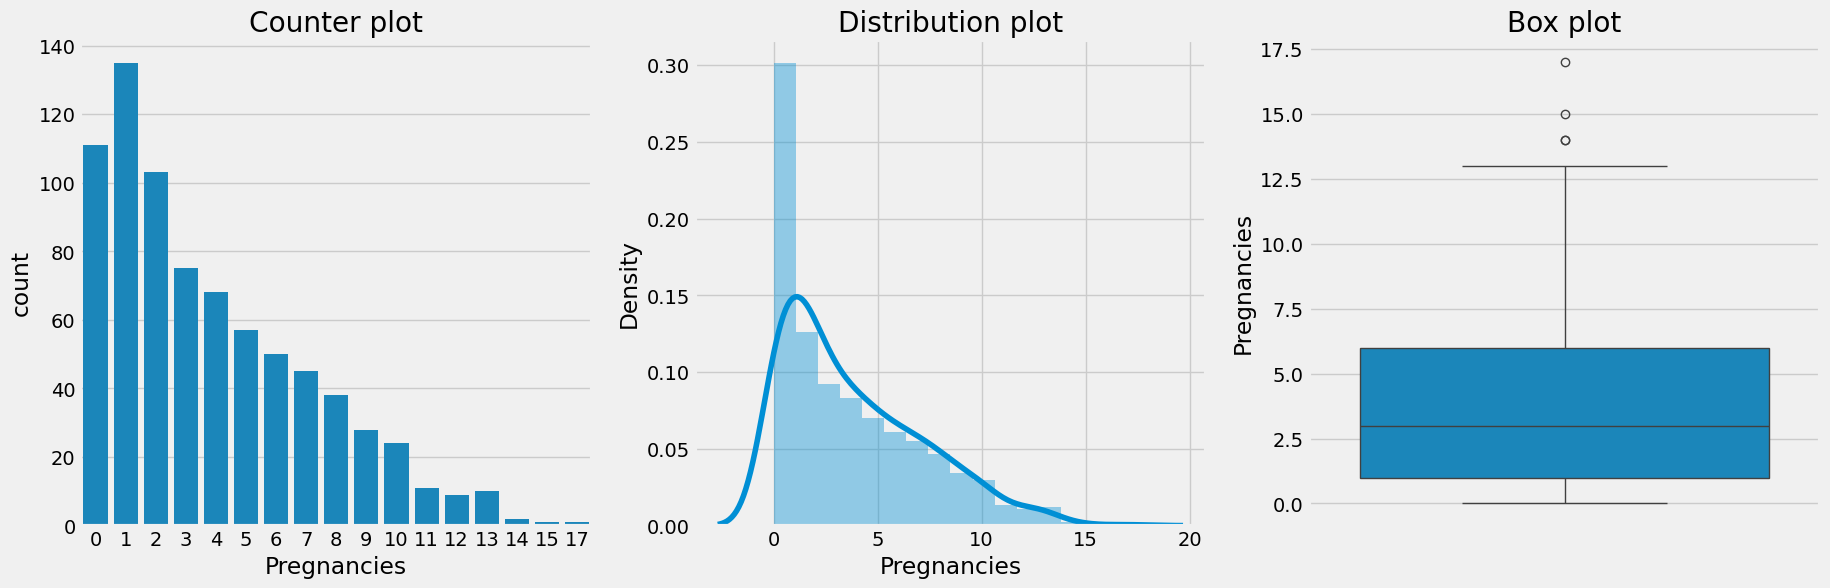

In [11]:
plt.figure(figsize=(20,6))
plt.subplot(1,3,1)
plt.title('Counter plot')
sns.countplot(x='Pregnancies',data=df)

plt.subplot(1,3,2)
plt.title('Distribution plot')
sns.distplot(df['Pregnancies'])

plt.subplot(1,3,3)
plt.title('Box plot')
sns.boxplot(y=df['Pregnancies'])

plt.show()

<Axes: ylabel='Age'>

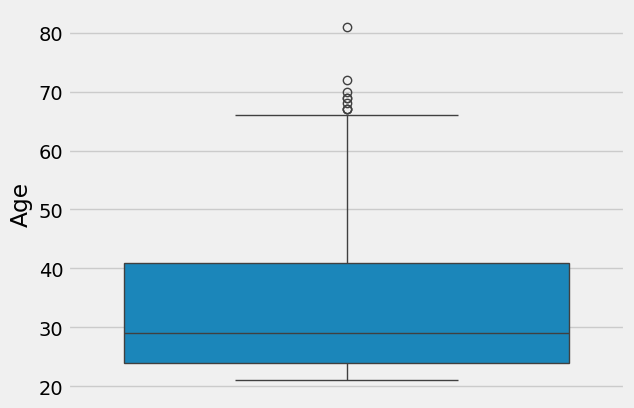

In [12]:
sns.boxplot(df.Age)

## Create Model 

In [13]:
x=df.drop('Outcome',axis=1)
y=df['Outcome']

In [14]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2)

In [15]:
model1=LogisticRegression()
model2=SVC()
model3=RandomForestClassifier()
model4=GradientBoostingClassifier(n_estimators=1000)

In [16]:
columns=['LogisticRegression','SVC','RandomForestClassifier','GradientBoostingClassifier']
result1=[]
result2=[]
result3=[]

In [17]:
def cal(model):
    model.fit(x_train,y_train)
    pre=model.predict(x_test)
    accuracy=accuracy_score(pre,y_test)
    recall=recall_score(pre,y_test)
    f1=f1_score(pre,y_test)
    result1.append(accuracy)
    result2.append(recall)
    result3.append(f1)
    sns.heatmap(confusion_matrix(pre,y_test),annot=True)
    print(model)
    print("The Accuracy is",accuracy,"The Recall is:",recall ,"The F1 is :",f1)


LogisticRegression()
The Accuracy is 0.7987012987012987 The Recall is: 0.7608695652173914 The F1 is : 0.693069306930693


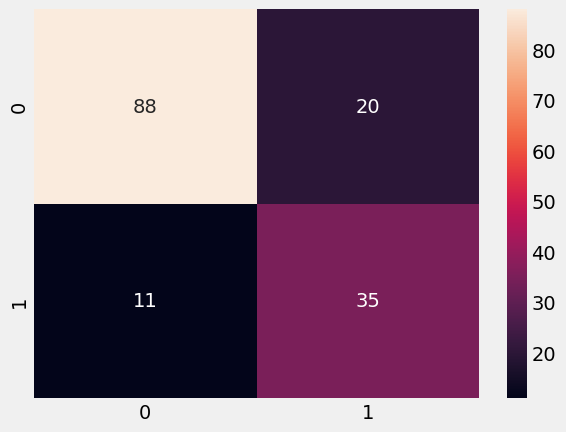

In [18]:
cal(model1)

SVC()
The Accuracy is 0.7532467532467533 The Recall is: 0.7297297297297297 The F1 is : 0.5869565217391305


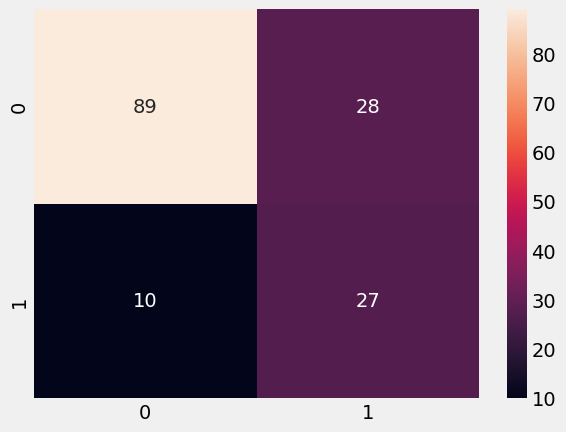

In [19]:
cal(model2)

RandomForestClassifier()
The Accuracy is 0.7922077922077922 The Recall is: 0.7017543859649122 The F1 is : 0.7142857142857143


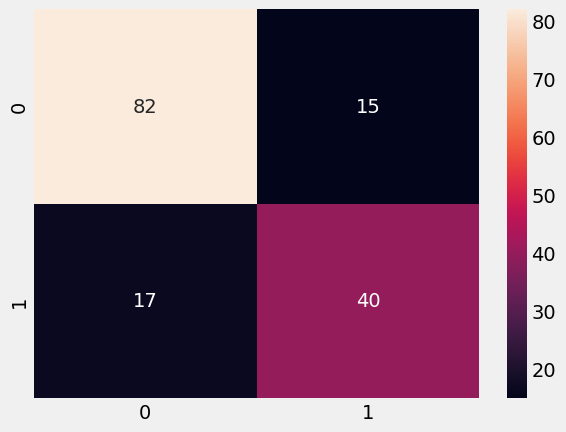

In [20]:
cal(model3)

GradientBoostingClassifier(n_estimators=1000)
The Accuracy is 0.7337662337662337 The Recall is: 0.6346153846153846 The F1 is : 0.616822429906542


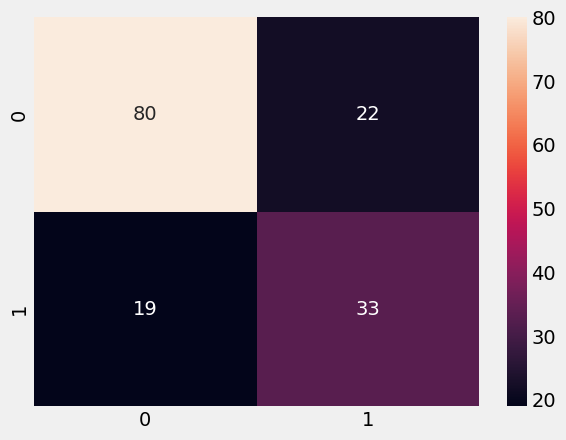

In [21]:
cal(model4)

In [22]:
Final_Result=pd.DataFrame({'Algorithm':columns,
                           'Accuracies':result1,
                           'Recall':result2 ,
                           'F1 Score':result3})
Final_Result

,Algorithm,Accuracies,Recall,F1 Score
0,LogisticRegression,0.798701,0.760870,0.693069
1,SVC,0.753247,0.729730,0.586957
2,RandomForestClassifier,0.792208,0.701754,0.714286
3,GradientBoostingClassifier,0.733766,0.634615,0.616822


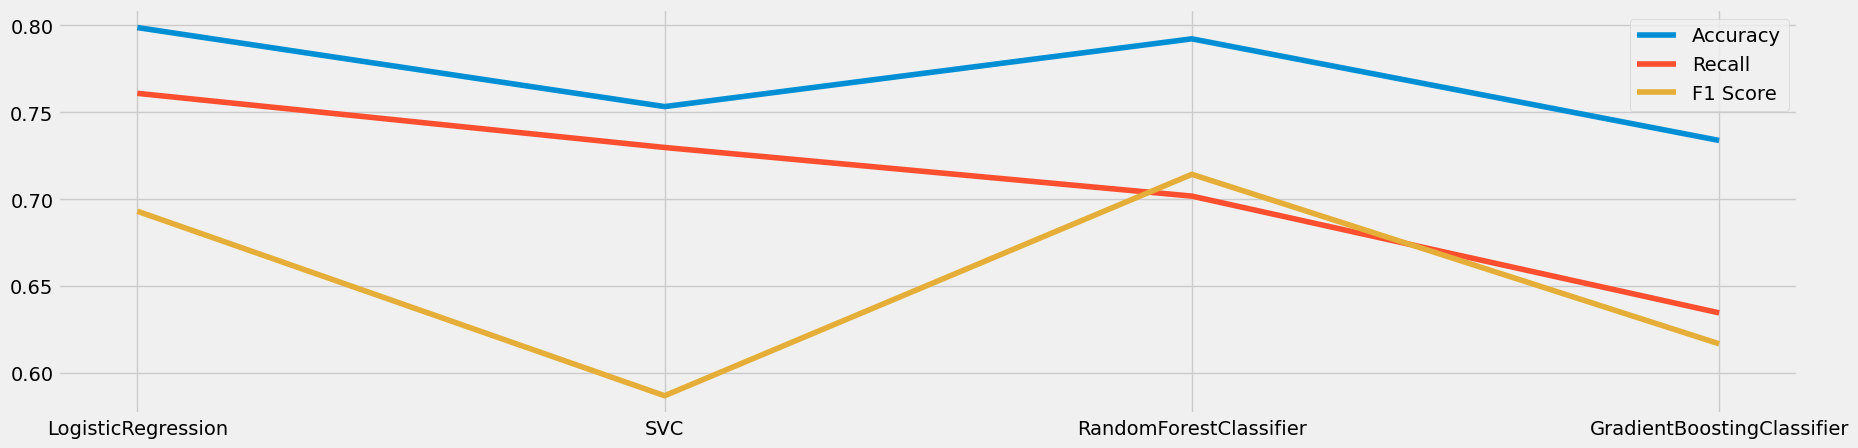

In [23]:
fig,ax=plt.subplots(figsize=(20,5))
plt.plot(Final_Result.Algorithm,result1,label="Accuracy")
plt.plot(Final_Result.Algorithm,result2,label="Recall")
plt.plot(Final_Result.Algorithm,result3,label="F1 Score")
plt.legend()
plt.show()

## create model From Sratch

In [24]:
# SVM from Scratch 


class SimpleSVM:
    def __init__(self, learning_rate=0.001, C=1.0, n_iters=1000):
        self.lr = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.w = None
        self.b = None
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        y_ = np.where(y == 0, -1, 1)
        
        self.w = np.zeros(n_features)
        self.b = 0
        
        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.w) + self.b) >= 1
                if condition:
                    dw = 2 * (1/self.C) * self.w
                    db = 0
                else:
                    dw = 2 * (1/self.C) * self.w - np.dot(x_i, y_[idx])
                    db = -y_[idx]
                
                self.w -= self.lr * dw
                self.b -= self.lr * db
    
    def predict(self, X):
        decision = np.dot(X, self.w) + self.b
        return np.where(decision >= 0, 1, 0)


# ========== Load and Prepare Data ==========
print("="*50)
print("SVM FROM SCRATCH")
print("="*50)

X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values



# ========== Split Data ==========
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

# ========== Feature Scaling ==========
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ========== Train SVM with Different Parameters ==========
print("\n" + "="*50)
print("TRAINING SVM WITH DIFFERENT PARAMETERS")
print("="*50)

best_accuracy = 0
best_params = {}
best_model = None
results = []

#LR = Learning Rate (معدل التعلم)
#C = Regularization Parameter (معامل التنظيم)
for lr in [0.001, 0.005, 0.01, 0.05]:
    for c in [0.1, 1.0, 5.0, 10.0]:
        svm = SimpleSVM(learning_rate=lr, C=c, n_iters=500)
        svm.fit(X_train, y_train)
        y_pred = svm.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        
        results.append({'LR': lr, 'C': c, 'Accuracy': acc})
        
        if acc > best_accuracy:
            best_accuracy = acc
            best_params = {'LR': lr, 'C': c}
            best_model = svm
        
        print(f"LR={lr}, C={c} => Accuracy: {acc:.4f}")

# ========== Best Model Results ==========
print("\n" + "="*50)
print("BEST MODEL RESULTS")
print("="*50)

print(f"\nBest Parameters:")
print(f"  Learning Rate: {best_params['LR']}")
print(f"  C (Regularization): {best_params['C']}")
print(f"  Iterations: 500")

# Predict with best model
y_pred_best = best_model.predict(X_test)

print(f"\n{'='*40}")
print(f"ACCURACY: {best_accuracy:.4f} = {best_accuracy*100:.2f}%")
print(f"{'='*40}")

print(f"\nPrecision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_best):.4f}")

print(f"\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))



SVM FROM SCRATCH

Training samples: 614
Testing samples: 154

TRAINING SVM WITH DIFFERENT PARAMETERS
LR=0.001, C=0.1 => Accuracy: 0.6429
LR=0.001, C=1.0 => Accuracy: 0.6429
LR=0.001, C=5.0 => Accuracy: 0.7792
LR=0.001, C=10.0 => Accuracy: 0.8052
LR=0.005, C=0.1 => Accuracy: 0.6429
LR=0.005, C=1.0 => Accuracy: 0.6429
LR=0.005, C=5.0 => Accuracy: 0.7922
LR=0.005, C=10.0 => Accuracy: 0.8117
LR=0.01, C=0.1 => Accuracy: 0.6429
LR=0.01, C=1.0 => Accuracy: 0.6429
LR=0.01, C=5.0 => Accuracy: 0.7792
LR=0.01, C=10.0 => Accuracy: 0.7987
LR=0.05, C=0.1 => Accuracy: 0.6429
LR=0.05, C=1.0 => Accuracy: 0.6494
LR=0.05, C=5.0 => Accuracy: 0.7792
LR=0.05, C=10.0 => Accuracy: 0.8182

BEST MODEL RESULTS

Best Parameters:
  Learning Rate: 0.05
  C (Regularization): 10.0
  Iterations: 500

ACCURACY: 0.8182 = 81.82%

Precision: 0.7647
Recall:    0.7091
F1-Score:  0.7358

Confusion Matrix:
[[87 12]
 [16 39]]


In [25]:
!pip install mlflow

In [26]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ==========================================
# 1. تقسيم البيانات (استخدام x, y الموجودين عندك)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# ==========================================
# 2. تعريف النماذج
# ==========================================
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=200, random_state=42)
}

# ==========================================
# 3. تدريب وتسجيل كل نموذج في MLflow
# ==========================================
for model_name, model in models.items():
    # كل نموذج ياخد تجربة منفصلة في MLflow
    mlflow.set_experiment(f"Diabetes_{model_name}")
    
    with mlflow.start_run(run_name=f"Diabetes_{model_name}_Run"):
        # تدريب النموذج
        model.fit(X_train, y_train)
        
        # التنبؤ وحساب الدقة
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        
        # تسجيل البارامترات والمقاييس
        if model_name == "RandomForest":
            mlflow.log_params({
                "n_estimators": 100,
                "random_state": 42
            })
        elif model_name == "GradientBoosting":
            mlflow.log_params({
                "n_estimators": 100,
                "learning_rate": 0.1,
                "random_state": 42
            })
        elif model_name == "LogisticRegression":
            mlflow.log_params({
                "max_iter": 200,
                "random_state": 42
            })
        
        mlflow.log_metric("accuracy", accuracy)
        
        # حفظ النموذج (بالصيغة الآمنة)
        mlflow.sklearn.log_model(
            sk_model=model,
            name=f"{model_name.lower()}_diabetes_model",
            serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
        )
        
        print(f"✅ {model_name} Accuracy on Diabetes: {accuracy:.3f} ({accuracy*100:.2f}%)")

✅ RandomForest Accuracy on Diabetes: 0.721 (72.08%)
✅ GradientBoosting Accuracy on Diabetes: 0.740 (74.03%)
✅ LogisticRegression Accuracy on Diabetes: 0.747 (74.68%)


In [32]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# استخدمي بيانات الديابيتيز (x, y موجودين عندك من قبل)
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

mlflow.set_experiment("GradientBoosting_Diabetes")

with mlflow.start_run(run_name="GB_Diabetes_100"):
    model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
    model.fit(X_train, y_train)
    
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    mlflow.log_params({
        "n_estimators": 100,
        "learning_rate": 0.1
    })
    mlflow.log_metric("accuracy", accuracy)
    
    mlflow.sklearn.log_model(
        sk_model=model,
        name="gradient_boosting_diabetes_model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
    )
    
    print(f"✅ GradientBoosting Accuracy on Diabetes: {accuracy:.3f}")

✅ GradientBoosting Accuracy on Diabetes: 0.740


In [28]:
import mlflow
import mlflow.sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# استخدمي بيانات الديابيتيز (x, y موجودين عندك)
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

mlflow.set_experiment("LogisticRegression_Diabetes")

with mlflow.start_run(run_name="LR_Diabetes"):
    model = LogisticRegression(max_iter=200, random_state=42)
    model.fit(X_train, y_train)
    
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    mlflow.log_params({
        "max_iter": 200,
        "C": 1.0
    })
    mlflow.log_metric("accuracy", accuracy)
    
    mlflow.sklearn.log_model(
        sk_model=model,
        name="logistic_regression_diabetes_model",
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS
    )
    
    print(f"✅ LogisticRegression Accuracy on Diabetes: {accuracy:.3f}")

✅ LogisticRegression Accuracy on Diabetes: 0.747


In [29]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# استخدام المتغيرات الموجودة (x, y)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

mlflow.set_experiment("Diabetes_Experiments_Skops")

with mlflow.start_run(run_name="RF_Diabetes_Safe"):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    
    accuracy = accuracy_score(y_test, model.predict(X_test))
    
    # 1. تسجيل الباراميترات والمقاييس
    mlflow.log_param("n_estimators", 100)
    mlflow.log_metric("accuracy", accuracy)
    
    # 2. حفظ النموذج بالطريقة الآمنة (skops)
    mlflow.sklearn.log_model(
        sk_model=model,
        name="diabetes_model",  # ✅ استخدام 'name' بدلاً من 'artifact_path'
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_SKOPS  # ✅ الصيغة الآمنة
    )
    
    print(f"✅ RandomForest Accuracy on Diabetes: {accuracy:.3f}")

✅ RandomForest Accuracy on Diabetes: 0.721


In [31]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

# جيب آخر Run في تجربة RandomForest
experiment = client.get_experiment_by_name("Diabetes_RandomForest")
runs = client.search_runs(experiment.experiment_id)

for run in runs:
    print(f"Run ID: {run.info.run_id}")
    print(f"Metrics: {run.data.metrics}")
    print(f"Parameters: {run.data.params}")
    print("-" * 40)

Run ID: 47db3720327a4b188ddd053ad3458da2
Metrics: {'accuracy': 0.7207792207792207}
Parameters: {'n_estimators': '100', 'random_state': '42'}
----------------------------------------
Run ID: 5d89ec185d7547d0911367a4f02467e0
Metrics: {'accuracy': 0.7207792207792207}
Parameters: {'n_estimators': '100', 'random_state': '42'}
----------------------------------------


In [33]:
import pandas as pd
from mlflow.tracking import MlflowClient

client = MlflowClient()
results = []

# هات كل التجارب اللي فيها Diabetes في اسمها
experiments = client.search_experiments()
for exp in experiments:
    if "Diabetes" in exp.name:
        runs = client.search_runs(exp.experiment_id)
        for run in runs:
            results.append({
                "📌 التجربة (Experiment)": exp.name,
                "🎯 الدقة (Accuracy)": run.data.metrics.get("accuracy", "N/A"),
                "🆔 Run ID": run.info.run_id[:8],
            })

# اعرض النتيجة في جدول مرتب
df = pd.DataFrame(results)
print(df.to_string(index=False))

     📌 التجربة (Experiment)  🎯 الدقة (Accuracy) 🆔 Run ID
Diabetes_LogisticRegression            0.746753 4f567bab
Diabetes_LogisticRegression            0.746753 83856617
  Diabetes_GradientBoosting            0.740260 98192414
  Diabetes_GradientBoosting            0.740260 b0aa9115
      Diabetes_RandomForest            0.720779 47db3720
      Diabetes_RandomForest            0.720779 5d89ec18
LogisticRegression_Diabetes            0.746753 c5626426
LogisticRegression_Diabetes            0.746753 f63026f2
LogisticRegression_Diabetes            0.746753 bad781ed
  GradientBoosting_Diabetes            0.740260 0c264ab8
  GradientBoosting_Diabetes            0.740260 f0d121a1
  GradientBoosting_Diabetes            0.740260 b3c4a005
  GradientBoosting_Diabetes            0.740260 28c9bf1e
 Diabetes_Experiments_Skops            0.720779 b0a875b5
 Diabetes_Experiments_Skops            0.720779 c6d8a4eb
 Diabetes_Experiments_Skops            0.720779 fd47b302
 Diabetes_Experiments_Skops    